# Training chunk의 $X_T$ 오른쪽 꼬리 분석

`ANALYZE_MODELS`에서 BS/Heston 분석 대상을 선택합니다. 각 `multiple`에 대해 $X_T \ge \log(\mathrm{multiple})$인 학습 표본의 비율을 정확히 계산하고, 분포 그림과 재분석용 CSV를 저장합니다. 대용량 데이터를 메모리에 모두 올리지 않도록 모든 파일을 행 배치 단위로 두 번 읽습니다.

In [4]:
import os
import warnings
from pathlib import Path

import h5py
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Unable to import Axes3D.*")
    import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 분석 대상 선택:
# ("bs",)          -> BS만
# ("hes",)         -> Heston만
# ("bs", "hes") -> 둘 다
ANALYZE_MODELS = ("hes",)
if os.environ.get("XT_ANALYSIS_MODELS"):
    ANALYZE_MODELS = tuple(
        model.strip().lower()
        for model in os.environ["XT_ANALYSIS_MODELS"].split(",")
        if model.strip()
    )
ANALYZE_MODELS = tuple(dict.fromkeys(ANALYZE_MODELS))
invalid_models = set(ANALYZE_MODELS) - {"bs", "hes"}
if not ANALYZE_MODELS or invalid_models:
    raise ValueError(
        f"ANALYZE_MODELS는 'bs', 'hes' 중 하나 이상이어야 합니다: {ANALYZE_MODELS}"
    )

DEFAULT_BS_CHUNK_DIR = (
    Path("E:/bs_chunks_correction")
    if os.name == "nt" else Path("/mnt/e/bs_chunks_correction")
)
DEFAULT_HESTON_CHUNK_DIR = (
    Path("E:/heston_chunks_correction")
    if os.name == "nt" else Path("/mnt/e/heston_chunks_correction")
)
BS_CHUNK_DIR = Path(os.environ.get("BS_CHUNK_DIR", DEFAULT_BS_CHUNK_DIR))
HESTON_CHUNK_DIR = Path(
    os.environ.get("HESTON_CHUNK_DIR", DEFAULT_HESTON_CHUNK_DIR)
)
CHUNK_COUNT = int(os.environ.get("XT_ANALYSIS_CHUNK_COUNT", "100"))
ROW_BATCH_SIZE = int(
    os.environ.get("XT_ANALYSIS_ROW_BATCH_SIZE", "1000000")
)
HISTOGRAM_BINS = int(
    os.environ.get("XT_ANALYSIS_HISTOGRAM_BINS", "20000")
)
OUTPUT_DIR = Path(
    os.environ.get("XT_ANALYSIS_OUTPUT_DIR", "result/tail_analysis")
)

MULTIPLES = np.array([20, 30, 40, 50, 60, 70, 80, 90, 100, 150])
LOG_THRESHOLDS = np.log(MULTIPLES.astype(np.float64))
CUTOFF_BIN_EDGES = np.concatenate(([-np.inf], LOG_THRESHOLDS, [np.inf]))
QUANTILE_PROBABILITIES = np.array([0.999, 0.9999, 0.99999])
MODEL_CONFIG = {
    "bs": {"chunk_dir": BS_CHUNK_DIR, "file_prefix": "bs"},
    "hes": {"chunk_dir": HESTON_CHUNK_DIR, "file_prefix": "heston"},
}

if CHUNK_COUNT < 1 or ROW_BATCH_SIZE < 1 or HISTOGRAM_BINS < 2:
    raise ValueError("chunk 수와 batch 크기는 양수이고 histogram bin은 2 이상이어야 합니다.")


In [5]:
def _expected_chunk_paths(model):
    config = MODEL_CONFIG[model]
    chunk_dir = Path(config["chunk_dir"])
    prefix = config["file_prefix"]
    paths = [
        chunk_dir / f"{prefix}_chunk_{index:03d}.h5"
        for index in range(CHUNK_COUNT)
    ]
    missing = [path for path in paths if not path.is_file()]
    if missing:
        preview = ", ".join(str(path) for path in missing[:5])
        suffix = f" 외 {len(missing) - 5}개" if len(missing) > 5 else ""
        raise FileNotFoundError(
            f"{model.upper()} chunk 파일 누락: {preview}{suffix}"
        )
    return paths


def _new_streaming_stats():
    return {
        "total_rows": 0,
        "finite_rows": 0,
        "nonfinite_count": 0,
        "mean": 0.0,
        "m2": 0.0,
        "min_x_t": np.inf,
        "max_x_t": -np.inf,
    }


def _update_streaming_stats(stats, values):
    values = np.asarray(values, dtype=np.float64)
    stats["total_rows"] += int(values.size)
    finite_values = values[np.isfinite(values)]
    stats["nonfinite_count"] += int(values.size - finite_values.size)
    if finite_values.size == 0:
        return finite_values

    batch_n = int(finite_values.size)
    batch_mean = float(finite_values.mean())
    batch_m2 = float(np.square(finite_values - batch_mean).sum())
    old_n = stats["finite_rows"]
    new_n = old_n + batch_n
    delta = batch_mean - stats["mean"]
    stats["mean"] += delta * batch_n / new_n
    stats["m2"] += batch_m2 + delta * delta * old_n * batch_n / new_n
    stats["finite_rows"] = new_n
    stats["min_x_t"] = min(stats["min_x_t"], float(finite_values.min()))
    stats["max_x_t"] = max(stats["max_x_t"], float(finite_values.max()))
    return finite_values


def _merge_streaming_stats(target, source):
    target["total_rows"] += source["total_rows"]
    target["nonfinite_count"] += source["nonfinite_count"]
    source_n = source["finite_rows"]
    if source_n == 0:
        return
    target_n = target["finite_rows"]
    combined_n = target_n + source_n
    delta = source["mean"] - target["mean"]
    target["mean"] += delta * source_n / combined_n
    target["m2"] += (
        source["m2"] + delta * delta * target_n * source_n / combined_n
    )
    target["finite_rows"] = combined_n
    target["min_x_t"] = min(target["min_x_t"], source["min_x_t"])
    target["max_x_t"] = max(target["max_x_t"], source["max_x_t"])


def _finalize_streaming_stats(stats):
    finite_rows = stats["finite_rows"]
    if finite_rows == 0:
        return {
            "total_rows": stats["total_rows"],
            "finite_rows": 0,
            "nonfinite_count": stats["nonfinite_count"],
            "mean_x_t": np.nan,
            "std_x_t": np.nan,
            "min_x_t": np.nan,
            "max_x_t": np.nan,
        }
    return {
        "total_rows": stats["total_rows"],
        "finite_rows": finite_rows,
        "nonfinite_count": stats["nonfinite_count"],
        "mean_x_t": stats["mean"],
        "std_x_t": float(np.sqrt(stats["m2"] / finite_rows)),
        "min_x_t": stats["min_x_t"],
        "max_x_t": stats["max_x_t"],
    }


def _iter_x_t_batches(chunk_path):
    with h5py.File(chunk_path, "r") as h5_file:
        if "paths" not in h5_file:
            raise KeyError(f"{chunk_path}: 'paths' 데이터셋이 없습니다.")
        paths = h5_file["paths"]
        if paths.ndim != 2 or paths.shape[1] < 2:
            raise ValueError(
                f"{chunk_path}: paths shape={paths.shape}, X_T 열(1)이 필요합니다."
            )
        for start in range(0, int(paths.shape[0]), ROW_BATCH_SIZE):
            end = min(start + ROW_BATCH_SIZE, int(paths.shape[0]))
            yield np.asarray(paths[start:end, 1], dtype=np.float64)


def _first_pass(model, chunk_paths):
    overall_stats = _new_streaming_stats()
    overall_exceed_counts = np.zeros(len(MULTIPLES), dtype=np.int64)
    chunk_rows = []
    chunk_cutoff_rows = []

    for completed, chunk_path in enumerate(chunk_paths, start=1):
        chunk_stats = _new_streaming_stats()
        chunk_exceed_counts = np.zeros(len(MULTIPLES), dtype=np.int64)
        for x_t in _iter_x_t_batches(chunk_path):
            finite_x_t = _update_streaming_stats(chunk_stats, x_t)
            interval_counts = np.histogram(finite_x_t, bins=CUTOFF_BIN_EDGES)[0]
            chunk_exceed_counts += np.cumsum(interval_counts[:0:-1])[::-1]

        _merge_streaming_stats(overall_stats, chunk_stats)
        finalized = _finalize_streaming_stats(chunk_stats)
        chunk_index = completed - 1
        chunk_rows.append({
            "model": model,
            "chunk_index": chunk_index,
            "chunk_file": str(chunk_path),
            **finalized,
        })
        finite_rows = finalized["finite_rows"]
        for multiple, threshold, exceed_count in zip(
            MULTIPLES, LOG_THRESHOLDS, chunk_exceed_counts
        ):
            chunk_cutoff_rows.append({
                "model": model,
                "chunk_index": chunk_index,
                "chunk_file": str(chunk_path),
                "multiple": int(multiple),
                "log_multiple": float(threshold),
                "comparison": "X_T >= log(multiple)",
                "finite_rows": finite_rows,
                "exceed_count": int(exceed_count),
                "exceed_pct_of_finite": (
                    100.0 * exceed_count / finite_rows if finite_rows else np.nan
                ),
            })
        overall_exceed_counts += chunk_exceed_counts
        print(f"[{model.upper()}] {completed}/{len(chunk_paths)}개 1차 통계 완료")

    overall_finalized = _finalize_streaming_stats(overall_stats)
    if overall_finalized["finite_rows"] == 0:
        raise ValueError(f"{model.upper()}: 유한한 X_T 값이 없습니다.")
    overall_row = {"model": model, **overall_finalized}
    cutoff_rows = []
    finite_rows = overall_finalized["finite_rows"]
    for multiple, threshold, exceed_count in zip(
        MULTIPLES, LOG_THRESHOLDS, overall_exceed_counts
    ):
        cutoff_rows.append({
            "model": model,
            "multiple": int(multiple),
            "log_multiple": float(threshold),
            "comparison": "X_T >= log(multiple)",
            "finite_rows": finite_rows,
            "nonfinite_count": overall_finalized["nonfinite_count"],
            "exceed_count": int(exceed_count),
            "exceed_fraction_of_finite": exceed_count / finite_rows,
            "exceed_pct_of_finite": 100.0 * exceed_count / finite_rows,
            "empirical_percentile_pct": 100.0 * (1.0 - exceed_count / finite_rows),
        })
    return overall_row, cutoff_rows, chunk_rows, chunk_cutoff_rows


def _histogram_quantiles(model, chunk_paths, overall_row):
    minimum = float(overall_row["min_x_t"])
    maximum = float(overall_row["max_x_t"])
    if minimum == maximum:
        padding = max(abs(minimum) * 1e-6, 1e-6)
        minimum -= padding
        maximum += padding
    edges = np.linspace(minimum, maximum, HISTOGRAM_BINS + 1)
    counts = np.zeros(HISTOGRAM_BINS, dtype=np.int64)

    for completed, chunk_path in enumerate(chunk_paths, start=1):
        for x_t in _iter_x_t_batches(chunk_path):
            finite_x_t = x_t[np.isfinite(x_t)]
            if finite_x_t.size:
                counts += np.histogram(finite_x_t, bins=edges)[0]
        print(f"[{model.upper()}] {completed}/{len(chunk_paths)}개 히스토그램 완료")

    finite_rows = int(overall_row["finite_rows"])
    if int(counts.sum()) != finite_rows:
        raise RuntimeError(
            f"{model.upper()}: histogram count {counts.sum():,} != finite rows {finite_rows:,}"
        )
    widths = np.diff(edges)
    centers = edges[:-1] + widths / 2.0
    cumulative_counts = np.cumsum(counts)
    survival_counts = np.cumsum(counts[::-1])[::-1]
    histogram_rows = [
        {
            "model": model,
            "bin_index": index,
            "bin_left": float(edges[index]),
            "bin_right": float(edges[index + 1]),
            "bin_center": float(centers[index]),
            "count": int(counts[index]),
            "density": float(counts[index] / (finite_rows * widths[index])),
            "cumulative_fraction": float(cumulative_counts[index] / finite_rows),
            "survival_pct_from_bin_left": float(100.0 * survival_counts[index] / finite_rows),
        }
        for index in range(HISTOGRAM_BINS)
    ]

    quantile_rows = []
    for probability in QUANTILE_PROBABILITIES:
        target = float(probability * finite_rows)
        bin_index = min(
            int(np.searchsorted(cumulative_counts, target, side="left")),
            HISTOGRAM_BINS - 1,
        )
        previous_count = int(cumulative_counts[bin_index - 1]) if bin_index else 0
        bin_count = int(counts[bin_index])
        within_bin = (target - previous_count) / bin_count if bin_count else 0.5
        within_bin = float(np.clip(within_bin, 0.0, 1.0))
        estimate = float(edges[bin_index] + within_bin * widths[bin_index])
        quantile_rows.append({
            "model": model,
            "probability": float(probability),
            "percentile_pct": float(100.0 * probability),
            "x_t_quantile_estimate": estimate,
            "implied_multiple_estimate": float(np.exp(estimate)),
            "method": "histogram_linear_interpolation",
            "histogram_bins": HISTOGRAM_BINS,
            "bin_left": float(edges[bin_index]),
            "bin_right": float(edges[bin_index + 1]),
            "bin_count": bin_count,
        })
    return histogram_rows, quantile_rows


def _plot_x_t_distributions(histogram_summary, cutoff_summary, output_path):
    model_count = len(ANALYZE_MODELS)
    figure, axes = plt.subplots(
        model_count, 2, figsize=(14, 4.5 * model_count), squeeze=False
    )
    colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(MULTIPLES)))

    for row_index, model in enumerate(ANALYZE_MODELS):
        histogram = histogram_summary[histogram_summary["model"] == model]
        cutoffs = cutoff_summary[cutoff_summary["model"] == model]
        distribution_axis, tail_axis = axes[row_index]

        distribution_axis.plot(
            histogram["bin_center"], histogram["density"],
            color="tab:blue", linewidth=1.2, drawstyle="steps-mid",
        )
        distribution_axis.set_title(f"{model.upper()} training $X_T$ distribution")
        distribution_axis.set_xlabel(r"$X_T = \log(S_T/S_0)$")
        distribution_axis.set_ylabel("Density")
        distribution_axis.grid(alpha=0.2)

        positive_tail = histogram["survival_pct_from_bin_left"] > 0
        tail_axis.semilogy(
            histogram.loc[positive_tail, "bin_center"],
            histogram.loc[positive_tail, "survival_pct_from_bin_left"],
            color="tab:purple", linewidth=1.2,
        )
        for color, (_, cutoff) in zip(colors, cutoffs.iterrows()):
            threshold = float(cutoff["log_multiple"])
            distribution_axis.axvline(threshold, color=color, alpha=0.35, linewidth=0.8)
            tail_axis.scatter(
                [threshold], [cutoff["exceed_pct_of_finite"]],
                color=color, s=28, zorder=3,
                label=f"{int(cutoff['multiple'])}x",
            )
        tail_axis.set_title(f"{model.upper()} right-tail survival")
        tail_axis.set_xlabel("$X_T$ cutoff")
        tail_axis.set_ylabel(r"$P(X_T \geq x)$ (%)")
        tail_axis.grid(alpha=0.2, which="both")
        tail_axis.legend(ncol=2, fontsize=8, title="multiple")

    figure.tight_layout()
    figure.savefig(output_path, dpi=180, bbox_inches="tight")
    if "agg" not in plt.get_backend().lower():
        plt.show()
    plt.close(figure)


[HES] 1/100개 1차 통계 완료
[HES] 2/100개 1차 통계 완료
[HES] 3/100개 1차 통계 완료
[HES] 4/100개 1차 통계 완료
[HES] 5/100개 1차 통계 완료
[HES] 6/100개 1차 통계 완료
[HES] 7/100개 1차 통계 완료
[HES] 8/100개 1차 통계 완료
[HES] 9/100개 1차 통계 완료
[HES] 10/100개 1차 통계 완료
[HES] 11/100개 1차 통계 완료
[HES] 12/100개 1차 통계 완료
[HES] 13/100개 1차 통계 완료
[HES] 14/100개 1차 통계 완료
[HES] 15/100개 1차 통계 완료
[HES] 16/100개 1차 통계 완료
[HES] 17/100개 1차 통계 완료
[HES] 18/100개 1차 통계 완료
[HES] 19/100개 1차 통계 완료
[HES] 20/100개 1차 통계 완료
[HES] 21/100개 1차 통계 완료
[HES] 22/100개 1차 통계 완료
[HES] 23/100개 1차 통계 완료
[HES] 24/100개 1차 통계 완료
[HES] 25/100개 1차 통계 완료
[HES] 26/100개 1차 통계 완료
[HES] 27/100개 1차 통계 완료
[HES] 28/100개 1차 통계 완료
[HES] 29/100개 1차 통계 완료
[HES] 30/100개 1차 통계 완료
[HES] 31/100개 1차 통계 완료
[HES] 32/100개 1차 통계 완료
[HES] 33/100개 1차 통계 완료
[HES] 34/100개 1차 통계 완료
[HES] 35/100개 1차 통계 완료
[HES] 36/100개 1차 통계 완료
[HES] 37/100개 1차 통계 완료
[HES] 38/100개 1차 통계 완료
[HES] 39/100개 1차 통계 완료
[HES] 40/100개 1차 통계 완료
[HES] 41/100개 1차 통계 완료
[HES] 42/100개 1차 통계 완료
[HES] 43/100개 1차 통계 완료
[HES] 44/100개 1차 통계 

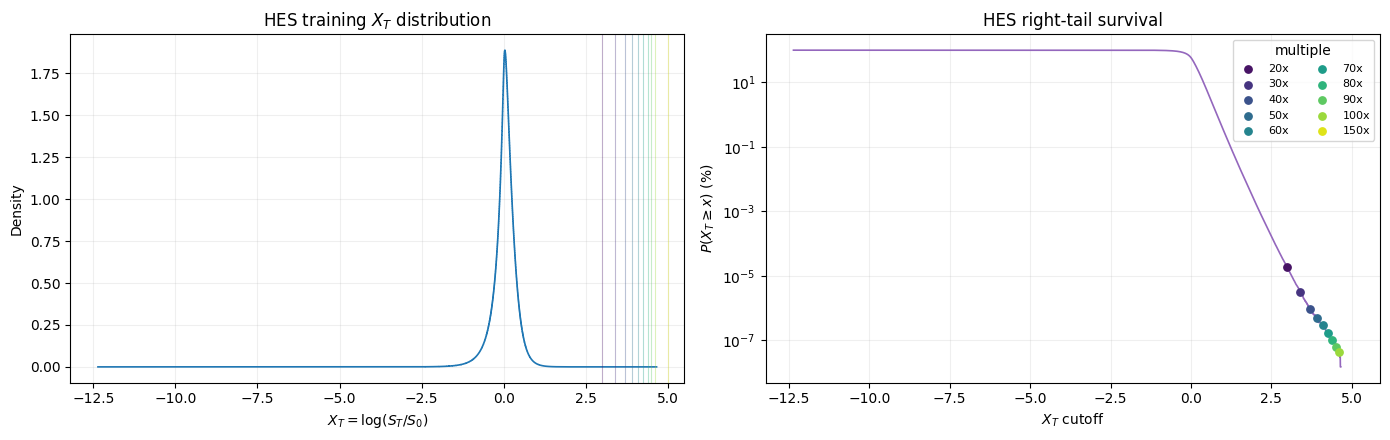

Saved: result/tail_analysis/xt_distribution.png

X_T cutoff별 학습표본 제거 비율 (유한한 X_T 기준)
model  multiple  log_multiple  exceed_count  exceed_pct_of_finite  empirical_percentile_pct
  hes        20      2.995732          1240          1.847744e-05                 99.999982
  hes        30      3.401197           214          3.188848e-06                 99.999997
  hes        40      3.688879            61          9.089708e-07                 99.999999
  hes        50      3.912023            34          5.066395e-07                 99.999999
  hes        60      4.094345            20          2.980232e-07                100.000000
  hes        70      4.248495            11          1.639128e-07                100.000000
  hes        80      4.382027             7          1.043081e-07                100.000000
  hes        90      4.499810             4          5.960464e-08                100.000000
  hes       100      4.605170             3          4.470348e-08                100.00

In [6]:
overall_rows = []
cutoff_rows = []
chunk_rows = []
chunk_cutoff_rows = []
histogram_rows = []
quantile_rows = []

for model in ANALYZE_MODELS:
    model_chunk_paths = _expected_chunk_paths(model)
    (
        model_overall,
        model_cutoffs,
        model_chunks,
        model_chunk_cutoffs,
    ) = _first_pass(model, model_chunk_paths)
    model_histogram, model_quantiles = _histogram_quantiles(
        model, model_chunk_paths, model_overall
    )
    overall_rows.append(model_overall)
    cutoff_rows.extend(model_cutoffs)
    chunk_rows.extend(model_chunks)
    chunk_cutoff_rows.extend(model_chunk_cutoffs)
    histogram_rows.extend(model_histogram)
    quantile_rows.extend(model_quantiles)

overall_summary = pd.DataFrame(overall_rows)
cutoff_summary = pd.DataFrame(cutoff_rows)
chunk_summary = pd.DataFrame(chunk_rows)
chunk_cutoff_summary = pd.DataFrame(chunk_cutoff_rows)
histogram_summary = pd.DataFrame(histogram_rows)
quantile_summary = pd.DataFrame(quantile_rows)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_tables = {
    "xt_overall_summary.csv": overall_summary,
    "xt_cutoff_summary.csv": cutoff_summary,
    "xt_chunk_summary.csv": chunk_summary,
    "xt_chunk_cutoff_summary.csv": chunk_cutoff_summary,
    "xt_quantile_summary.csv": quantile_summary,
    "xt_histogram.csv": histogram_summary,
}
for filename, table in output_tables.items():
    output_path = OUTPUT_DIR / filename
    table.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

distribution_path = OUTPUT_DIR / "xt_distribution.png"
_plot_x_t_distributions(histogram_summary, cutoff_summary, distribution_path)
print(f"Saved: {distribution_path}")

print("\nX_T cutoff별 학습표본 제거 비율 (유한한 X_T 기준)")
print(
    cutoff_summary[[
        "model", "multiple", "log_multiple",
        "exceed_count", "exceed_pct_of_finite",
        "empirical_percentile_pct",
    ]].to_string(index=False)
)
print("\n상위 분위수 (histogram 선형보간 추정)")
print(
    quantile_summary[[
        "model", "percentile_pct", "x_t_quantile_estimate",
        "implied_multiple_estimate", "method",
    ]].to_string(index=False)
)
